In [39]:
from langgraph.graph import StateGraph,MessagesState,START,END
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage,AIMessage
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import RemoveMessage
from dotenv import load_dotenv
load_dotenv()
import os 
os.environ['LANGCHAIN_PROJECT']="deleting_context"

In [40]:
model = ChatGroq( model="openai/gpt-oss-20b",
    temperature=0.7)

In [41]:
def delete_state(state:MessagesState):
    messages = state['messages']

    
    if len(messages)>10:
        to_delete = messages[:6]

        return {
            "messages":[RemoveMessage(id=m.id) for m in to_delete if m is not None]
        }
    return {}

checkpointer = InMemorySaver()

def chat_node(state:MessagesState):
    print("Current_length ->",len(state['messages']))
    res = model.invoke(f"Answer in {state['messages']}")

    return {"messages":[res.content]}


In [42]:
graph = StateGraph(MessagesState)

graph.add_node("delete_state",delete_state)
graph.add_node("chat_node",chat_node)


Adding an edge to a graph that has already been compiled. This will not be reflected in the compiled graph.
Adding an edge to a graph that has already been compiled. This will not be reflected in the compiled graph.


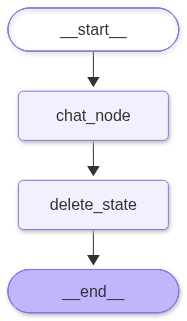

In [45]:
graph.add_edge(START,"chat_node")
graph.add_edge("chat_node","delete_state")

final_graph = graph.compile(checkpointer=checkpointer)
final_graph

In [44]:
from langchain_core.runnables import RunnableConfig

config: RunnableConfig = {
    "configurable": {
        "thread_id": "thread1"
    }
}

res1 = final_graph.invoke(
    {"messages": [HumanMessage(content="What is LangGraph used for? answer in 50 words")]},
    config=config
)

res2 = final_graph.invoke(
    {"messages": [HumanMessage(content="Explain short-term memory in LangGraph.answer in 50 words")]},
    config=config
)

res3 = final_graph.invoke(
    {"messages": [HumanMessage(content="How does message trimming work?answer in 50 words")]},
    config=config
)

res4 = final_graph.invoke(
    {"messages": [HumanMessage(content="What is the purpose of a checkpointer?answer in 50 words")]},
    config=config
)

res5 = final_graph.invoke(
    {"messages": [HumanMessage(content="How can I reduce token usage in an LLM application?answer in 50 words")]},
    config=config
)

res6 = final_graph.invoke(
    {"messages": [HumanMessage(content="Summarize the main concepts of this notebook.answer in 50 words")]},
    config=config
)
res7 = final_graph.invoke(
    {"messages": [HumanMessage(content="who was first cheif justice  of india .answer in 50 words")]},
    config=config
)

Current_length -> 1
Current_length -> 3
Current_length -> 5
Current_length -> 7
Current_length -> 9
Current_length -> 11
Current_length -> 7
